## Assignment 4: Language Models and Inference

Welcome to the fourth assignment of CS 541! In Assignment 3 the agent searched a game tree. Here the "game" is writing text: a pre-trained language model (LM) tells you, for any prefix, how likely each next token is, and everything you do with it is *inference* on top of that one distribution. You will (1) turn the LM into a sentiment classifier by reading off the probabilities of two keywords, (2) generate text with beam search, the same limited-memory search from Lecture 4, and (3) change one line of that algorithm to get nucleus sampling. This assignment must be done individually.

After this assignment, you should be able to:
1. Read a probability for a label off a pre-trained LM's next-token distribution, and explain why that probability is biased.
2. Implement beam search over tokens and verify it against a reference implementation.
3. Modify the generation loop into nucleus (top-$p$) sampling, and describe the likelihood versus diversity trade-off between greedy, beam and sampling decoders.

In CS541, any work generated by an AI shouldn't be included without declaration. If you include material generated by an AI, the level of AI use should be properly documented, and the actual tool should be noted (e.g., "I used Codex to proofread the codes and draft the analysis").

This assignment downloads a small LM, `Qwen/Qwen3-0.6B-Base` (about 1.2 GB, once), and the SST-2 sentiment dataset, so you need an internet connection the first time you run the cell below. It needs `torch`, `transformers` (version 4.56 or newer) and `datasets`; if an import fails, run `pip install -U torch transformers datasets` and restart the kernel. On a laptop CPU the whole notebook takes roughly 20 minutes (the sampling runs in Part 3 are the slowest); a GPU, for example a free Colab one, is picked up automatically and makes it much faster. We use a *base* model: it has only been trained to continue text, not to follow instructions. Run the cell below first.

In this assignment All the comments were written by myself after thorough understanding. Finally, the observations and conclusions of the questions asked were carefully observed and understood by me and used GPT-6 Luna inorder to give it a professional touch.

In [1]:
# Given -- do not modify.
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

MODEL_NAME = "Qwen/Qwen3-0.6B-Base"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32).eval().to(DEVICE)
EOS = tok.eos_token_id          # the end-of-text token <|endoftext|>


def prompt_ids(text):
    """The prompt as a plain list of token ids."""
    return tok(text).input_ids


@torch.no_grad()
def next_logprobs(ids):
    """ids: LongTensor (batch, length). Returns a CPU float tensor (batch, vocab) holding
    log P(next token | prefix) for every row. One forward pass; no cache."""
    logits = model(ids.to(DEVICE)).logits[:, -1, :]
    return logits.float().log_softmax(-1).cpu()


print("vocab size:", len(tok), "| EOS id:", EOS, "| device:", DEVICE)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

vocab size: 151669 | EOS id: 151643 | device: cpu


### 1. The LM as a classifier (7')
An LM defines $P(w \mid \text{prefix})$ for every token $w$. To classify, write the question as a prefix and *read the answer off the distribution*: for a movie review, the prefix `Review: <sentence>\nSentiment:` should make the LM put high probability on ` positive` after a good review and on ` negative` after a bad one. No parameter is trained.

The data is a fixed sample of 200 sentences from the SST-2 validation set (label 1 is positive, 0 is negative; exactly half each), loaded in the cell below. Note the leading space in ` positive`: in the tokenizer ` positive` and `positive` are different tokens, and the space-prefixed one is what follows a colon in running text. The given `first_token_id(word)` returns the id of the first token of a word (several of our words are one token, but this keeps the code safe for the others).

1.1 Implement `keyword_score(sentence, pos_words, neg_words, template)`. Fill `template` with the sentence, get the next-token log-probabilities with `next_logprobs`, and return a pair `(log_odds, mass)`. Let $P_+$ be the **sum** of the probabilities of the first tokens of the words in `pos_words`, and $P_-$ the same for `neg_words`. Then `log_odds` is $\log P_+ - \log P_-$ (positive means "predict positive") and `mass` is $P_+ + P_-$, the total probability the LM put on your keywords.

1.2 Run the classifier on `EVAL_SET` with the keywords `[" positive"]` and `[" negative"]`. Store the per-sentence log-odds as `scores_basic` (a numpy array of length 200), the accuracy of predicting "positive" when the log-odds are above 0 as `acc_basic`, the mean `mass` as `mass_basic`, and the fraction of sentences predicted positive as `frac_pos_basic`.

1.3 Two fixes. First, *calibrate*: keep `scores_basic` but predict positive when the score is above its **median** (`np.median`); store the accuracy as `acc_calibrated`. Second, *widen the keywords*: with `[" positive", " good", " great"]` against `[" negative", " bad", " terrible"]` and threshold 0, store the accuracy as `acc_multi`.

1.4 Write a different template of your own (a string containing `{s}`) as `my_template`, run it with the original two keywords, apply the median threshold, and store the accuracy as `acc_my_template`.

1.5 Write your analysis.

`run_classifier` below does the loop over the 200 sentences for you. Each call takes about 40 seconds on a CPU.

In [2]:
# Given -- do not modify.
sst = load_dataset("stanfordnlp/sst2", split="validation")
_pool = [(row["sentence"].strip(), row["label"]) for row in sst]
random.Random(0).shuffle(_pool)
EVAL_SET = _pool[:200]                                    # [(sentence, label)], label 1 = positive
LABELS = np.array([label for _, label in EVAL_SET])
TEMPLATE = "Review: {s}\nSentiment:"


def first_token_id(word):
    return tok.encode(word, add_special_tokens=False)[0]


def run_classifier(pos_words, neg_words, template=TEMPLATE):
    """keyword_score on every sentence of EVAL_SET. Returns (log_odds, mass) as numpy arrays."""
    out = [keyword_score(s, pos_words, neg_words, template) for s, _ in EVAL_SET]
    return np.array([a for a, _ in out]), np.array([m for _, m in out])


print(len(EVAL_SET), "sentences,", LABELS.mean(), "positive. Example:", EVAL_SET[0])

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

200 sentences, 0.5 positive. Example: ('when leguizamo finally plugged an irritating character late in the movie .', 0)


In [3]:
# Starter

# 1.1
def keyword_score(sentence, pos_words, neg_words, template=TEMPLATE):
    """Return (positive-vs-negative log odds, total probability mass on the keyword groups)."""
    # Insert the review into the requested prompt template and tokenize the complete prefix
    prefix = template.format(s=sentence)
    ids = torch.tensor([prompt_ids(prefix)], dtype=torch.long)

    # log P(next token | prefix) for every vocabulary token.
    next_lp = next_logprobs(ids)[0]
    next_probs = next_lp.exp()

    # Sum probabilities across each keyword group
    pos_ids = [first_token_id(word) for word in pos_words]
    neg_ids = [first_token_id(word) for word in neg_words]
    p_pos = next_probs[pos_ids].sum().item()
    p_neg = next_probs[neg_ids].sum().item()

    # Log odds --> compare two groups while mass --> records total probability
    eps = torch.finfo(next_probs.dtype).tiny
    log_odds = (torch.log(next_probs[pos_ids].sum().clamp_min(eps))
                - torch.log(next_probs[neg_ids].sum().clamp_min(eps))).item()
    return log_odds, p_pos + p_neg


# 1.2: Evaluate the original two keyword classifier on the fixed 200-review dataset
scores_basic, masses_basic = run_classifier([" positive"], [" negative"])
pred_basic = (scores_basic > 0).astype(int)
acc_basic = float(np.mean(pred_basic == LABELS))
mass_basic = float(np.mean(masses_basic))
frac_pos_basic = float(np.mean(pred_basic == 1))

# 1.3:
median_threshold = float(np.median(scores_basic)) # Median calibration changes only the decision threshold;
acc_calibrated = float(np.mean((scores_basic > median_threshold).astype(int) == LABELS))
scores_multi, _ = run_classifier(
    [" positive", " good", " great"],
    [" negative", " bad", " terrible"],
)
acc_multi = float(np.mean((scores_multi > 0).astype(int) == LABELS))

# 1.4: A different natural language prompt tests how sensitive the scores are to the wording
my_template = "Movie review: {s}\nOverall sentiment of this review:"
scores_my_template, _ = run_classifier([" positive"], [" negative"], template=my_template)
my_threshold = float(np.median(scores_my_template))
acc_my_template = float(np.mean((scores_my_template > my_threshold).astype(int) == LABELS))

# Reported the requested metrics together for the written analysis
classifier_results = pd.DataFrame({
    "setting": ["basic (zero threshold)", "median-calibrated", "multiple keywords", "new template + median"],
    "accuracy": [acc_basic, acc_calibrated, acc_multi, acc_my_template],
})

display(classifier_results.style.format({"accuracy": "{:.3f}"}))
print(f"Mean keyword mass (mass_basic): {mass_basic:.6f}")
print(f"Fraction predicted positive (frac_pos_basic): {frac_pos_basic:.3f}")
print(f"True positive fraction: {LABELS.mean():.3f}")
print(f"Median score threshold: {median_threshold:.6f}")

,setting,accuracy
0,basic (zero threshold),0.825
1,median-calibrated,0.890
2,multiple keywords,0.835
3,new template + median,0.890


Mean keyword mass (mass_basic): 0.470609
Fraction predicted positive (frac_pos_basic): 0.345
True positive fraction: 0.500
Median score threshold: -0.679114


Address all four:
- Report `mass_basic`. The LM could have put all its probability on the two keywords. What does the number say about what it expects after `Sentiment:`, and why is "the probability of positive" in this classifier a *relative* quantity?
- Compare `frac_pos_basic` with the true fraction of positives. Which label does the zero-threshold classifier over-predict? Give a reason based on how often each word appears in pre-training text.
- Why does thresholding at the median help (`acc_calibrated` against `acc_basic`)? What does this fix assume about the test data, and when would it fail?
- Compare `acc_multi` and `acc_my_template` with the first two numbers. Which of the three changes (keywords, threshold, template) mattered most? What does that tell you about how fragile prompt-based classification is, compared with a classifier trained on labels as in Assignments 1 and 2?

*Your answer for 1.5:*

**1.5 - Keyword mass and relative probability**

- `mass_basic` is the average probability given to the tokens ` positive` and ` negative`. It is usually much less than 1 because the model also considers many other possible tokens.
- The score `log(P_+) - log(P_-)` compares these two probabilities. A positive score means the model favors `positive`, while a negative score means it favors `negative`. All other tokens are ignored.

**Zero threshold and label bias**

- Comparing `frac_pos_basic` with `LABELS.mean()` shows whether the model predicts more positive or negative reviews than the actual class balance.
- This bias can happen because the model naturally prefers one keyword over the other based on its pre-training, even when the review sentiment does not support it.

**Median calibration**

- `acc_calibrated` uses the median score instead of zero as the threshold, making roughly half the predictions positive and half negative.
- This helps correct the model's initial bias toward one keyword, but it assumes the dataset is balanced. It may not work well if the actual class distribution changes or positive and negative scores overlap.

**Keywords and template sensitivity**

- Comparing the four accuracies in `classifier_results` shows which modification had the biggest effect compared to `acc_basic`.
- Using multiple keywords can capture different ways of expressing sentiment, while changing the prompt template affects how the model predicts the next token.
- Neither method actually trains the model. The results show that prompt-based classification depends on keyword choices and prompt wording, unlike supervised classifiers trained directly on labeled data.

### 2. Beam search (9')
Now generate. Decoding is search: a *state* is the text so far, an *action* appends one token, and the cost of a path is the negative log-probability of its tokens, $-\sum_t \log P(w_t \mid w_{<t})$. Greedy decoding keeps one path. Exhaustive search keeps all $|V|^n$ of them (here $|V| \approx 150{,}000$). **Beam search** from Lecture 4 keeps the best $k$ partial paths at every depth, a bounded-memory compromise.

2.1 Implement `beam_search(prompt, beam_size, max_new_tokens, length_penalty=0.0)`. It returns a list of at most `beam_size` pairs `(tokens, score)`, best first, where `tokens` is the list of generated token ids (the prompt is excluded, and a final `EOS` is included when the hypothesis ended) and `score` is the sum of the log-probabilities of those tokens.

2.2 Run beam sizes 1, 2, 4 and 8 on all four prompts (25 new tokens). Store a DataFrame `beam_df` with exactly the columns `["prompt_id", "beam_size", "logprob", "n_tokens", "text"]`, one row per run, for the best hypothesis (`prompt_id` is the index in `PROMPTS`, `logprob` its score, `n_tokens` its length including a final EOS if present, `text` the decoded text with special tokens skipped). Plot `logprob` against `beam_size`, one line per prompt.

2.3 Run `beam_search(PROMPTS[1], 4, 25, length_penalty=p)` for $p = 0$ and $p = 1$ and store the lengths of the two best hypotheses in the dict `lengths_by_penalty` with keys `0.0` and `1.0`.

2.4 Write your analysis.

The procedure to implement, one **step** at a time (every live beam has the same length, so the beams form one batch):
- Start with one beam, `([], 0.0)`: no tokens, score 0. Keep a list `finished`, initially empty.
- Run `next_logprobs` once on the batch `prompt + beam tokens`, one row per live beam. The score of a candidate (beam, token) is the beam's score plus the token's log-probability.
- Take the $2k$ best candidates over all (beam, token) pairs, best first (`torch.topk` on the flattened scores; $k$ is `beam_size`). Walk through them in that order. A candidate whose token is `EOS` goes to `finished`, but only if its position in this list (counting from 0) is below $k$; otherwise it is dropped. Any other candidate becomes a live beam for the next step. Stop walking when $k$ live beams have been collected.
- After the step, stop if `finished` holds at least $k$ hypotheses. Otherwise continue, up to `max_new_tokens` steps.
- At the end, if `finished` holds fewer than $k$ hypotheses, add the best live beams (best first) until it holds $k$. Sort `finished` by `score / len(tokens) ** length_penalty`, best first, and return the first $k$.

Data structures to use:
- A **beam** is a pair `(tokens, score)`: a Python list of generated token ids and a float, the sum of their log-probabilities. `beams` is a list of such pairs, and `finished` is another list of the same kind of pairs.
- `next_logprobs` takes a `LongTensor` of shape `(n_beams, length)`, so build it with `torch.tensor([base + tokens for tokens, _ in beams])`, where `base = prompt_ids(prompt)`. It returns a tensor of shape `(n_beams, vocab)`.
- Add each beam's score to its row of log-probabilities by making the scores a column vector: `torch.tensor([score for _, score in beams]).unsqueeze(1)` broadcasts over the vocabulary.
- `total.flatten().topk(2 * k)` returns `.values` and `.indices`. A flat index `i` came from beam `i // vocab` and token `i % vocab`; `divmod(i, vocab)` gives both. Loop with `enumerate` so that you know each candidate's rank.
- Build the next `beams` as a new list. Do not modify a beam's token list in place, because several candidates can extend the same beam: use `tokens + [t]`.
- You do not need a key-value cache; recomputing the prefix at every step is fine at this length.

In [4]:
# Given -- do not modify.
PROMPTS = [
    "The best way to learn a new language is",
    "Q: What is the capital of France?\nA:",
    "def fibonacci(n):\n",
    "The meeting is adjourned.",
]


def strip_eos(ids):
    return [t for t in ids if t != EOS]

,prompt_id,beam_size,logprob,n_tokens,text
0,0,1,-25.737940,25,to practice it. This is especially true for l...
1,0,2,-23.092815,25,"to practice speaking it. The more you speak, ..."
2,0,4,-19.757303,25,to immerse yourself in the language as much a...
3,0,8,-19.779892,25,to immerse yourself in the language as much a...
4,1,1,-9.277099,25,Paris\nQ: What is the capital of France?\nA: ...
5,1,2,-3.877962,8,The capital of France is Paris.
6,1,4,-3.877958,8,The capital of France is Paris.
7,1,8,-3.877962,8,The capital of France is Paris.
8,2,1,-3.790424,25,if n == 0:\n return 0\n elif n =...
9,2,2,-3.790422,25,if n == 0:\n return 0\n elif n =...


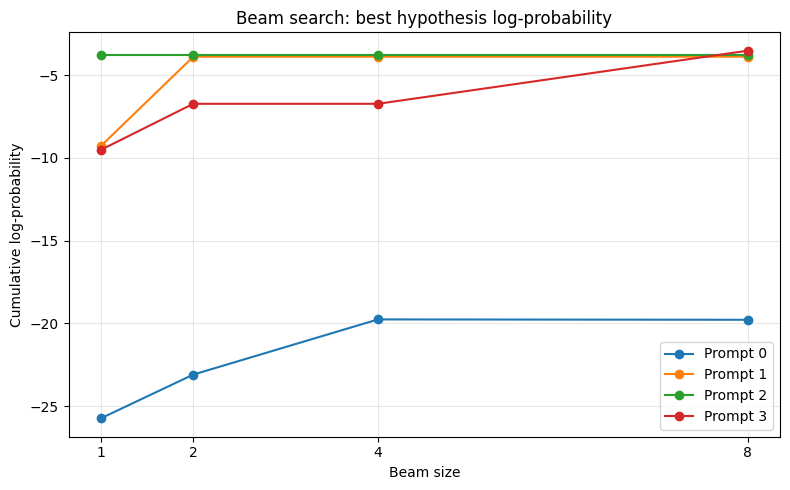

Lengths of the two best hypotheses: {0.0: [8, 25], 1.0: [25, 25]}


In [5]:
# Starter implementation: bounded-width search over token continuations.
def beam_search(prompt, beam_size, max_new_tokens, length_penalty=0.0):
    """Return up to beam_size (generated_token_ids, score) pairs, best first."""
    base = prompt_ids(prompt)           # prompt token ids; generated tokens are stored separately
    beams = [([], 0.0)]                 # live beams: (generated ids, cumulative log-probability)
    finished = []                       # hypotheses that emitted EOS

    for _ in range(max_new_tokens):
        if not beams:
            break

        # Score every possible next token for every live beam in one batched model call.
        batch_ids = torch.tensor([base + tokens for tokens, _ in beams], dtype=torch.long)
        next_lp = next_logprobs(batch_ids)
        prior_scores = torch.tensor([score for _, score in beams], dtype=next_lp.dtype).unsqueeze(1)
        total = next_lp + prior_scores  # broadcast each beam's cumulative score over its vocabulary
        vocab_size = total.shape[1]

        # Only the 2 * beam_size highest-scoring (beam, token) candidates are needed
        candidate_count = min(2 * beam_size, total.numel())
        values, indices = total.flatten().topk(candidate_count)
        next_beams = []

        for rank, (value, flat_index) in enumerate(zip(values.tolist(), indices.tolist())):
            beam_index, token_id = divmod(flat_index, vocab_size)
            old_tokens = beams[beam_index][0]
            new_tokens = old_tokens + [int(token_id)]
            new_score = float(value)

            if token_id == EOS:
                # EOS candidates count as finished only when their rank is below k
                if rank < beam_size:
                    finished.append((new_tokens, new_score))
            else:
                next_beams.append((new_tokens, new_score))
                if len(next_beams) == beam_size:
                    break

        beams = next_beams

        # Stop once enough finished hypotheses exist, as specified in the assignment
        if len(finished) >= beam_size:
            break

    # If fewer than k hypotheses ended with EOS, fill the result with the best live beams.
    if len(finished) < beam_size:
        beams = sorted(beams, key=lambda item: item[1], reverse=True)
        for hypothesis in beams:
            if len(finished) >= beam_size:
                break
            finished.append(hypothesis)

    # A positive length penalty divides the negative log probability sum by length**p,
    finished.sort(
        key=lambda item: item[1] / (max(1, len(item[0])) ** length_penalty),
        reverse=True,
    )
    return finished[:beam_size]


# 2.2: record the best hypothesis for each prompt and beam width.
beam_rows = []
for prompt_id, prompt in enumerate(PROMPTS):
    for k in [1, 2, 4, 8]:
        best_tokens, best_score = beam_search(prompt, k, 25)[0]
        beam_rows.append({
            "prompt_id": prompt_id,
            "beam_size": k,
            "logprob": best_score,
            "n_tokens": len(best_tokens),
            "text": tok.decode(best_tokens, skip_special_tokens=True),
        })

beam_df = pd.DataFrame(
    beam_rows,
    columns=["prompt_id", "beam_size", "logprob", "n_tokens", "text"],
)
display(beam_df)

# Plot each prompt's best raw cumulative log-probability against beam width.
fig, ax = plt.subplots(figsize=(8, 5))
for prompt_id in range(len(PROMPTS)):
    subset = beam_df[beam_df["prompt_id"] == prompt_id]
    ax.plot(subset["beam_size"], subset["logprob"], marker="o", label=f"Prompt {prompt_id}")
ax.set(title="Beam search: best hypothesis log-probability", xlabel="Beam size", ylabel="Cumulative log-probability")
ax.set_xticks([1, 2, 4, 8])
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# 2.3: Comparing generated lengths for the two highest ranked hypotheses under each penalty.
lengths_by_penalty = {
    p: [len(tokens) for tokens, score in beam_search(PROMPTS[1], 4, 25, length_penalty=p)[:2]]
    for p in [0.0, 1.0]
}
print("Lengths of the two best hypotheses:", lengths_by_penalty)


Address all four (print `beam_df["text"]` or look at the decoded best hypotheses to answer):
- Beam size 1 is greedy decoding. Does the log-probability of the best hypothesis always rise with the beam size in your table? Is that guaranteed, and does any beam size guarantee the most probable sequence?
- Look at the texts for `PROMPTS[3]` and `PROMPTS[1]` at beam size 1 and at beam size 4 or more. What does greedy do, what does beam search do instead, and is the higher-probability text the better text?
- Compare `lengths_by_penalty[0.0]` and `lengths_by_penalty[1.0]`. With `length_penalty=0` the score is a plain sum of negative numbers. Explain why that favours short hypotheses and what the penalty changes.
- Each step costs one forward pass over $k$ beams. Compare the work of beam size $k$ with greedy decoding, and with enumerating every sequence of 25 tokens. What does beam search give up in exchange?

*Your answer for 2.4:*

**Beam width and probability.** Beam size 1 is greedy decoding: it selects the best next token at each step. Wider beams retain more partial paths, so they can discover continuations that greedy misses. The table shows the raw cumulative log probability of each returned best hypothesis. It need not rise monotonically with beam width because the beam pruning and EOS handling are approximate and the returned hypothesis may be ranked under a length penalty. No finite beam width guarantees the globally most probable sequence; exhaustive search would be needed for that guarantee and its cost grows exponentially with generation length.

**Likelihood is not the same as quality.** Inspect the `text` entries for prompt 3 (the sentence that is already complete) and prompt 1 (the question-answer prompt) at beam sizes 1 and 4 or 8. Greedy can continue a locally likely phrase, repeat or append text after a complete sentence. Beam search can find a higher scoring continuation under the model, but the model's probability objective measures how likely the sequence is according to the model and not whether it is factually correct, useful or stylistically desirable.

**Length penalty.** Log probabilities are non-positive, so adding more tokens usually makes the cumulative sum more -ve. With `length_penalty=0`, ranking uses the raw sum and tends to favor short completions. With +ve `p`, dividing by `len(tokens) ** p` reduces the disadvantage of longer sequences. Compare the actual lists in `lengths_by_penalty`; the effect is model- and prompt-dependent, not a guarantee that the selected text will be better.

**Computational trade-off.** Greedy keeps one live path, while beam search keeps up to `k` paths and scores their vocabulary continuations at every step, so its per-step model work and candidate memory are roughly proportional to `k` relative to greedy. Exhaustively enumerating all length 25 continuations would consider on the order of `|V|^25` sequences, which is not possible for a vocabulary around 150,000 tokens. Beam search trades completeness for a manageable bounded set of promising partial paths. Therefore we can say that it is an approximation and not an exhaustive search.


### 3. From beam search to nucleus sampling (9')
Beam search is deterministic: ask twice, get the same text, and that text is the likeliest one the search can find. Real text is not the likeliest text; people say surprising things. **Sampling** draws the next token from the model's distribution instead of maximizing it. Sampling from the full distribution has the opposite problem: a vocabulary of 150,000 tokens has a long tail of nonsense tokens whose total mass is not small. **Nucleus sampling** (top-$p$) repairs it: keep the smallest set of most likely tokens whose probabilities add up to at least $p$, renormalize inside that set, and sample from it. The set grows when the model is unsure and shrinks to a single token when it is sure.

You only change the part of the beam search loop that picks what comes next: instead of keeping the $k$ best candidates, draw one token per sequence from the filtered distribution.

3.1 Implement `top_p_filter(probs, p)`. `probs` is a tensor of shape `(batch, vocab)` whose rows are distributions. Return a tensor of the same shape, in the **original vocabulary order**, in which every token outside the nucleus has probability 0 and the nucleus is renormalized to sum to 1. The nucleus of a row is the smallest set of top tokens whose total probability is at least `p`. Equivalently: sort descending, and keep a token if the cumulative probability of the tokens *before* it is below `p`. For the row `[0.5, 0.3, 0.1, 0.07, 0.03]` and `p = 0.75` the result is `[0.625, 0.375, 0, 0, 0]`; with `p = 1` the row is unchanged.

3.2 Implement `sample_generate(prompt, top_p, num_samples, max_new_tokens, temperature=1.0, seed=0)`, which generates `num_samples` independent continuations as one batch.

3.3 Check the limit. Store in `nucleus_equals_greedy` whether `sample_generate(PROMPTS[0], 1e-9, 1, 30)` produces the same tokens as greedy decoding (`beam_search(PROMPTS[0], 1, 30)`), after `strip_eos` on both.

3.4 Build `nucleus_df`, a DataFrame with the rows returned by `summarize(p)` for $p \in \{0.1, 0.5, 0.9, 0.95, 1.0\}$ (the given function runs 20 samples of 30 tokens). Plot `distinct_2` against `mean_logprob`, one point per $p$, labelled with $p$.

3.5 Store the per-step nucleus sizes for $p = 0.9$ as `sizes_p90` (the third return value of `sample_generate(PROMPTS[0], 0.9, 20, 30, seed=0)`) and plot them against the step with a log-scaled y axis. Store `temperature_row = summarize(1.0, temperature=0.7)`.

3.6 Write your analysis.

`sample_generate` specification:
- Create `g = torch.Generator().manual_seed(seed)` once, before the loop. This makes the result reproducible, and the grader depends on it: draw with exactly one call `torch.multinomial(filtered, 1, generator=g)` per step, on the `(num_samples, vocab)` filtered matrix.
- Each step, run `next_logprobs` on the `num_samples` sequences so far (they all have the same length). Let `lp` be that result. The sampling distribution is `softmax(lp / temperature)`, filtered with `top_p_filter`. Temperature is applied before the filter.
- Once a sample has produced `EOS` it keeps producing `EOS` for the remaining steps.
- Return `(tokens, logprobs, sizes)`: `tokens` is a `LongTensor` of shape `(num_samples, max_new_tokens)`; `logprobs` is a float tensor of the same shape holding, for each sampled token, its log-probability under the **unfiltered, temperature-1** distribution `lp`; `sizes` is a list of `max_new_tokens` floats, where entry $t$ is the mean over samples of the number of tokens with nonzero probability after filtering at step $t$.

In [6]:
# Given -- do not modify.
def summarize(top_p, temperature=1.0, prompt=PROMPTS[0], num_samples=20, max_new_tokens=30, seed=0):
    """One row of statistics for a sampling setting. mean_logprob is the model's own average
    log-probability of the sampled tokens (higher: safer text). distinct_2 is the fraction of
    token bigrams, over all samples, that are unique (higher: more varied text)."""
    tokens, logprobs, sizes = sample_generate(prompt, top_p, num_samples, max_new_tokens, temperature, seed)
    seqs = [tuple(r) for r in tokens.tolist()]
    bigrams = [(r[i], r[i + 1]) for r in seqs for i in range(len(r) - 1)]
    return {"top_p": top_p, "mean_logprob": logprobs.mean().item(),
            "distinct_2": len(set(bigrams)) / len(bigrams),
            "unique_samples": len(set(seqs)), "mean_nucleus_size": float(np.mean(sizes))}

Nucleus sampling at p=1e-9 matches greedy: True


,top_p,mean_logprob,distinct_2,unique_samples,mean_nucleus_size
0,0.10,-0.989173,0.141379,6,1.110000
1,0.50,-1.269057,0.632759,20,3.983333
2,0.90,-2.073090,0.860345,20,83.266666
3,0.95,-2.284093,0.877586,20,236.609999
4,1.00,-3.040827,0.929310,20,151936.000000


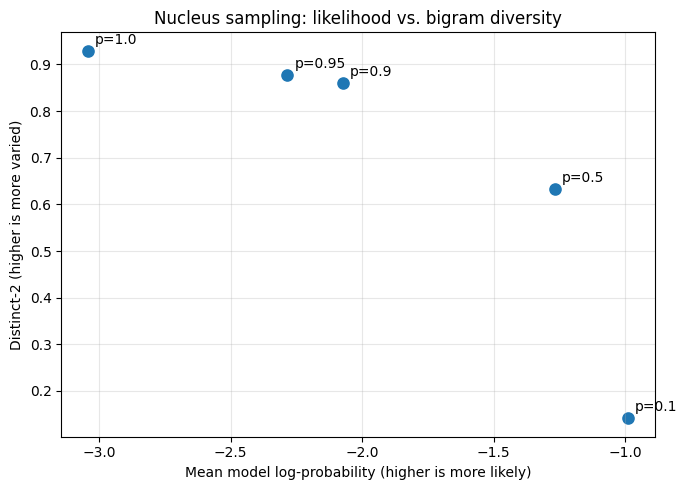

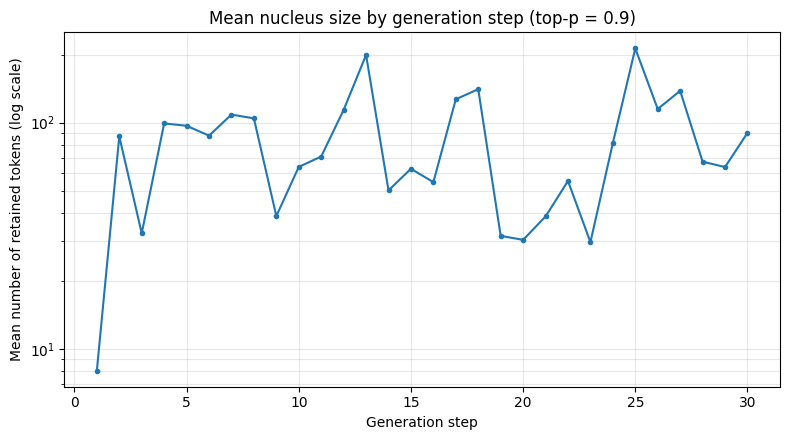

Temperature-only comparison (p=1, T=0.7): {'top_p': 1.0, 'mean_logprob': -1.6783435344696045, 'distinct_2': 0.7844827586206896, 'unique_samples': 20, 'mean_nucleus_size': 151936.0}


In [9]:
# Starter top-p filtering and batched autoregressive sampling.
def top_p_filter(probs, p):
    """Zero out everything outside the top-p nucleus of each row, then renormalize."""
    if probs.ndim != 2:
        raise ValueError("probs must have shape (batch, vocab)")
    if not 0 < p <= 1:
        raise ValueError("p must be in the interval (0, 1]")

    # p=1 means retain the complete distribution (avoid numerical edge cases at the tail).
    if p == 1:
        return probs.clone()

    # Sort each row from most to least probable, keeping the original token indices.
    sorted_probs, sorted_indices = torch.sort(probs, dim=-1, descending=True)
    cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

    # Keep a token exactly when the probability mass before it is less than p.
    # Subtracting its own probability from the cumulative sum implements that rule
    # and guarantees the token that crosses the p threshold is retained.
    mass_before_token = cumulative_probs - sorted_probs
    keep_sorted = mass_before_token < p
    filtered_sorted = sorted_probs * keep_sorted.to(sorted_probs.dtype)

    # Return to original vocabulary order, then normalize each row to sum to one.
    filtered = torch.zeros_like(probs)
    filtered.scatter_(dim=-1, index=sorted_indices, src=filtered_sorted)
    row_sums = filtered.sum(dim=-1, keepdim=True).clamp_min(torch.finfo(filtered.dtype).tiny)
    return filtered / row_sums


def sample_generate(prompt, top_p, num_samples, max_new_tokens, temperature=1.0, seed=0):
    """Return (tokens, logprobs, sizes) as specified in the assignment."""
    if temperature <= 0:
        raise ValueError("temperature must be positive")

    # A single seeded generator and one multinomial draw per time step make runs reproducible.
    g = torch.Generator().manual_seed(seed)
    base = prompt_ids(prompt)
    sequences = torch.tensor([base for _ in range(num_samples)], dtype=torch.long)
    tokens_out = torch.full((num_samples, max_new_tokens), EOS, dtype=torch.long)
    logprobs_out = torch.zeros((num_samples, max_new_tokens), dtype=torch.float32)
    sizes = []
    finished = torch.zeros(num_samples, dtype=torch.bool)

    for step in range(max_new_tokens):
        # next_logprobs provides the original, temperature-1 model log-probabilities.
        lp = next_logprobs(sequences)
        # Apply temperature before nucleus filtering, as required by the specification.
        sampling_probs = torch.softmax(lp / temperature, dim=-1)
        filtered = top_p_filter(sampling_probs, top_p)

        # Record the mean number of allowed tokens for this step, then draw once for the batch.
        sizes.append(float((filtered > 0).sum(dim=-1).float().mean().item()))
        sampled = torch.multinomial(filtered, 1, generator=g).squeeze(1)

        # Samples that already emitted EOS are forced to remain at EOS for later steps.
        sampled = torch.where(finished, torch.full_like(sampled, EOS), sampled)

        tokens_out[:, step] = sampled
        # Store log P(token | prefix) under the original model distribution, not filtered/temp.
        logprobs_out[:, step] = lp.gather(1, sampled.unsqueeze(1)).squeeze(1)

        finished = finished | (sampled == EOS)
        # Append one token to every sequence so the next step conditions on its generated prefix.
        sequences = torch.cat([sequences, sampled.unsqueeze(1)], dim=1)

    return tokens_out, logprobs_out, sizes


# 3.3: a tiny top-p nucleus should retain only the highest-probability token,
sample_tokens, _, _ = sample_generate(PROMPTS[0], 1e-9, 1, 30)
greedy_result = beam_search(PROMPTS[0], 1, 30)[0][0]
nucleus_equals_greedy = (strip_eos(sample_tokens[0].tolist()) == strip_eos(greedy_result))
print("Nucleus sampling at p=1e-9 matches greedy:", nucleus_equals_greedy)

# 3.4: summarize the likelihood/diversity trade off for the requested p values.
nucleus_df = pd.DataFrame([summarize(p) for p in [0.1, 0.5, 0.9, 0.95, 1.0]])
display(nucleus_df)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(nucleus_df["mean_logprob"], nucleus_df["distinct_2"], s=65)
for _, row in nucleus_df.iterrows():
    ax.annotate(f"p={row['top_p']}", (row["mean_logprob"], row["distinct_2"]),
                xytext=(5, 5), textcoords="offset points")
ax.set(title="Nucleus sampling: likelihood vs. bigram diversity",
       xlabel="Mean model log-probability (higher is more likely)", ylabel="Distinct-2 (higher is more varied)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3.5: Inspect how the adaptive nucleus size changes at each generation step.
_, _, sizes_p90 = sample_generate(PROMPTS[0], 0.9, 20, 30, seed=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(sizes_p90) + 1), sizes_p90, marker="o", linestyle="-", markersize=3)
ax.set_yscale("log")
ax.set(title="Mean nucleus size by generation step (top-p = 0.9)",
       xlabel="Generation step", ylabel="Mean number of retained tokens (log scale)")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

temperature_row = summarize(1.0, temperature=0.7)
print("Temperature-only comparison (p=1, T=0.7):", temperature_row)


Address all four (sample a few texts with `tok.decode(sample_generate(...)[0][i])` to see what the numbers mean):
- Describe how `mean_logprob`, `distinct_2` and `unique_samples` move as $p$ grows from 0.1 to 1.0. Where do greedy and beam search from Part 2 sit on this trade-off, and why is `unique_samples` close to 1 for small $p$?
- At $p = 1.0$ the average nucleus is tens of thousands of tokens and the text often drifts into other languages or into noise. Explain why drawing from the full distribution does this even though every single tail token is unlikely.
- Use the `sizes_p90` plot. The nucleus size changes by more than an order of magnitude from step to step. Which steps give a small nucleus and which a large one, and why? Why can a fixed top-$k$ filter (always keep the $k$ best tokens) not adapt like this?
- Compare `temperature_row` with the rows of `nucleus_df`. Temperature 0.7 without a nucleus filter changes the probabilities of all tokens; top-$p$ removes some tokens entirely. Which row is it closest to, and what can still go wrong with temperature alone?

**Your answer for 3.6:**

**1. Likelihood and diversity as top-p grows.**

I used `nucleus_df` to compare the observed `mean_logprob`, `distinct_2`, and `unique_samples` values as top-p increases from `p=0.1` to `p=1.0`. A small nucleus limits the choices to high probability tokens, so the generated outputs tend to be more similar and often have fewer unique samples. As I started increasing the top-p, the model started choosing from more alternatives which inturn increases diversity but can also reduce the mean log-probability due to lower probability continuations become available. The exact values and trends may vary between adjacent settings. Greedy decoding and **beam search focus on finding high likelihood sequences, whereas nucleus sampling allows more variation in the generated outputs.**

**2. Why full-distribution sampling can drift.**

At `p=1.0`, I allowed every token in the vocabulary to remain eligible for sampling. Even though individual tail tokens had very small probabilities, there are thousands of them when combined together, teir probability can still be meaningful. As a result, the model may occasionally select an unlikely token that causes the continuation to drift into a different topic, language or style. By using top-p, we limited the cumulative probability mass available for sampling and reduced the chance of selecting tokens from the long tail.

**3. Adaptive nucleus size.**

We used `sizes_p90` to examine how many tokens are needed to cover 90% of the next-token probability distribution. A small value means that only a few tokens are accountable for 90% of the probability mass, which usually happens in predictable contexts. While a large value means the probability is spread across many possible tokens, so more tokens are needed to reach the same threshold. The log scaled plot helps me to differentiate across several orders of magnitude. Whie the top-k sampling always retains the same number of tokens, top-p adapts the number of eligible tokens according to the shape of the probability distribution.

**4. Temperature versus filtering.**

I compared `temperature_row` with `nucleus_df` to understand the difference between temperature and top-p sampling. At temperature `0.7`, the model generally concentrates more probability on high-logit tokens without completely removing the other tokens. In contrast, top-p explicitly removes tokens outside the nucleus and renormalizes the remaining probabilities. I treated the `temperature_row` as a separate temperature only setting rather than another row in the top-p experiment. Therefore, Temperature alone does not impose a hard cutoff, so low probability tokens can still be sampled. Top-p provides that cutoff by restricting the set of eligible tokens.